In [64]:
import time
import warnings
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / 'models' / 'src'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
import keras
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor

from common import contract, data, metrics, paths, plots
import mlp

SAIDA = paths.EXPORT_MLP

SEMENTE = contract.SEED
FEATURES = mlp.ENTRADAS

OCULTAS = (256, 128, 64)
EPOCHS = 400
BATCH = 128
PACIENCIA = 30
LR = 3e-4
HUBER_DELTA = 10.0

keras.utils.set_random_seed(SEMENTE)
np.random.seed(SEMENTE)

print("tensorflow", tf.__version__, "| keras", keras.__version__)
print("entrada:", paths.SPLITS)
print("saida  :", SAIDA)
print(f"entradas: {len(FEATURES)} -> {', '.join(FEATURES)}")


tensorflow 2.21.0 | keras 3.15.1
entrada: C:\Users\gusta\Documents\PlatformIO\Projects\knob-senses\data\splited
saida  : C:\Users\gusta\Documents\PlatformIO\Projects\knob-senses\data\modelo_exportado
entradas: 3 -> temperatura_ambiente, ghit, jacques


## 2. Carga e sanidade

In [65]:
dados, MINIMO, MAXIMO = mlp.prepara()

X_tre, y_tre = dados["treino"]["X"], dados["treino"]["y"]
X_val, y_val = dados["validacao"]["X"], dados["validacao"]["y"]
X_tes, y_tes = dados["teste"]["X"], dados["teste"]["y"]

for nome, X, y in (("treino", X_tre, y_tre), ("validacao", X_val, y_val),
                   ("teste", X_tes, y_tes)):
    print(f"{nome:10} {len(X):6} amostras de {X.shape[1]:2} entradas | "
          f"PCA {y.min():.2f}..{y.max():.2f} kW | media {y.mean():.3f}")

PCA_MIN, PCA_MAX = data.target_limits()

# Guarda de faixa: o contrato fisico do alvo e' [PCA_MIN, PCA_MAX]. Se este aviso
# aparecer, o split e o contrato divergem - confira o dataset_prep antes de confiar
# nas metricas.
for nome, y in (("treino", y_tre), ("validacao", y_val), ("teste", y_tes)):
    fora = int(((y < PCA_MIN) | (y > PCA_MAX)).sum())
    if fora:
        print(f"ATENCAO: {nome}: {fora}/{len(y)} alvos fora de "
              f"[{PCA_MIN}, {PCA_MAX}] kW - contrato/dataset_prep divergem")

assert len(X_tes) > 100, f"teste ficou com so {len(X_tes)} amostras"
assert X_tre.dtype == np.float32 and X_tes.dtype == np.float32
print("\nOK: X em [0, 1] (min-max ajustado so no treino)")


treino       1820 amostras de  3 entradas | PCA 35.45..171.18 kW | media 116.736
validacao     980 amostras de  3 entradas | PCA 37.10..169.10 kW | media 115.121
teste         354 amostras de  3 entradas | PCA 38.04..161.71 kW | media 114.478

OK: X em [0, 1] (min-max ajustado so no treino)


## 3. Métricas

Três números, em kW todos os três (R² é adimensional):

- **MAE** — o erro típico. É a métrica de cabeça: compare com a potência do inversor
  (~2 kW) para ter noção de escala.
- **RMSE** — igual ao MAE, mas pune erro grande com mais força.
- **R²** — fração da variância explicada.

O julgamento é **no split de teste**, que é o futuro. A validação só serve para
early stopping e para escolher hiperparâmetro; usá-la para reportar seria escolher a
dedo o resultado.

In [66]:
def avalia(nome, y, pred):
    """As metricas do projeto, em kW - a mesma funcao dos outros dois notebooks."""
    return metrics.evaluate(nome, y, pred)


resultados = []


## 4. Piso: a média do treino

O modelo mais burro possível que ainda acerta a média. Se um modelo de verdade não
bater isto com folga, ele não aprendeu nada.

In [67]:
media = DummyRegressor(strategy="mean").fit(X_tre, y_tre)
resultados.append(avalia("media do treino", y_tes, media.predict(X_tes).ravel()))

media do treino      MAE 21.4791 kW | RMSE 26.2138 kW | R2 -0.0075 | vies +2.2586 kW


## 5. Random Forest — referência

`n_estimators=300` com `min_samples_leaf=2`. Não há busca de hiperparâmetro: o RF aqui
é régua, não candidato — o Edge Impulse não aceita modelo sklearn.

Se a rede Keras ficar muito atrás do RF, é sinal de que a arquitetura ou o treino
precisam de atenção. Se ficar perto, a rede está boa e é ela que vai para o firmware,
porque é a única que o Edge Impulse sabe compilar para o ESP32.

In [68]:
rf = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=2,
    n_jobs=-1,
    random_state=SEMENTE,
)

t0 = time.perf_counter()
rf.fit(X_tre, y_tre)
print(f"treino do RF: {time.perf_counter() - t0:.1f} s")

pred_rf = rf.predict(X_tes)
resultados.append(avalia("random forest", y_tes, pred_rf))

treino do RF: 0.4 s
random forest        MAE 3.2483 kW | RMSE 4.4397 kW | R2 0.9711 | vies +1.9909 kW


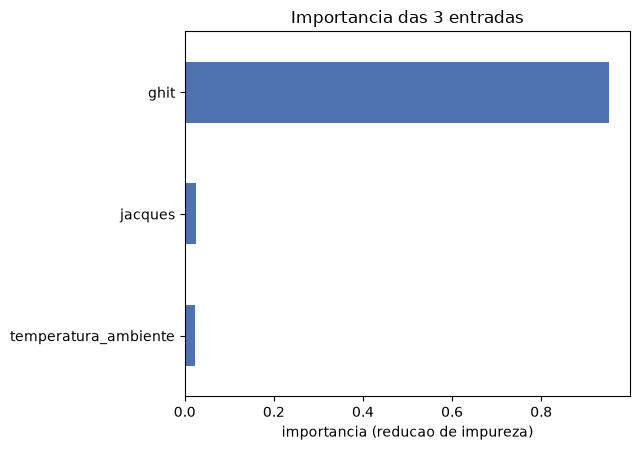

temperatura_ambiente    0.0239
jacques                 0.0244
ghit                    0.9517


In [69]:
importancia = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()

plots.plot_importancia(importancia,
                       titulo=f"Importancia das {len(FEATURES)} entradas")

print(importancia.round(4).to_string())


## 6. Rede Keras — o modelo exportado

as entradas do contrato -> 64 -> 32 -> 1: densa, ReLU nas escondidas e **linear na saída**.

Decisões que valem registro:

- **Entrada achatada, não sequencial.** Um MLP denso não sabe que a entrada é uma série;
  as entradas são as features do contrato.
- **Saída linear e em kW, sem normalizar o alvo.** A rede prevê kW direto; o firmware
  não precisa desfazer transformação nenhuma na saída.
- **Rede pequena de propósito.** O Edge Impulse compila isto para o compilador EON /
  ESP32; rede maior aqui não compra acurácia e só encarece o binário.
- **Early stopping no `val_loss`**, com `restore_best_weights`. Paciência de 25 épocas,
  teto de 200. O `ReduceLROnPlateau` corta a taxa de aprendizado pela metade após 8
  épocas sem melhora (piso `1e-5`).


In [70]:
camadas = [keras.layers.Input(shape=(len(FEATURES),), name="features")]
for i, n in enumerate(OCULTAS):
    camadas.append(keras.layers.Dense(n, activation="relu", name=f"oculta_{i}"))
media_y = float(y_tre.mean())
camadas.append(keras.layers.Dense(
    1, name="pca_kw",
    bias_initializer=keras.initializers.Constant(media_y)))

modelo = keras.Sequential(camadas, name="knob_senses_pca")
modelo.compile(optimizer=keras.optimizers.Adam(LR),
               loss=keras.losses.Huber(delta=HUBER_DELTA), metrics=["mae"])
modelo.summary()


Model: "knob_senses_pca"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ oculta_0 (Dense)                │ (None, 256)            │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_1 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_2 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pca_kw (Dense)                  │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 42,241 (165.00 KB)

 Trainable params: 42,241 (165.00 KB)

 Non-trainable params: 0 (0.00 B)

In [71]:
chamadas = [
    keras.callbacks.EarlyStopping(monitor="val_mae", patience=PACIENCIA,
                                  restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_mae", factor=0.5, patience=8,
                                      min_lr=1e-5, verbose=1),
]

t0 = time.perf_counter()
historico = modelo.fit(
    X_tre, y_tre,
    validation_data=(X_val, y_val),
    epochs=EPOCHS, batch_size=BATCH, callbacks=chamadas, verbose=0,
)
print(f"treino da rede: {time.perf_counter() - t0:.1f} s")
print(f"parou na epoca {len(historico.history['loss'])} "
      f"(melhor val_mae {min(historico.history['val_mae']):.5f})")



Epoch 110: ReduceLROnPlateau reducing learning rate to 0.0001500000071246177.

Epoch 203: ReduceLROnPlateau reducing learning rate to 7.500000356230885e-05.

Epoch 219: ReduceLROnPlateau reducing learning rate to 3.7500001781154424e-05.

Epoch 227: ReduceLROnPlateau reducing learning rate to 1.8750000890577212e-05.

Epoch 235: ReduceLROnPlateau reducing learning rate to 1e-05.
Epoch 241: early stopping
Restoring model weights from the end of the best epoch: 211.
treino da rede: 27.0 s
parou na epoca 241 (melhor val_mae 6.23161)


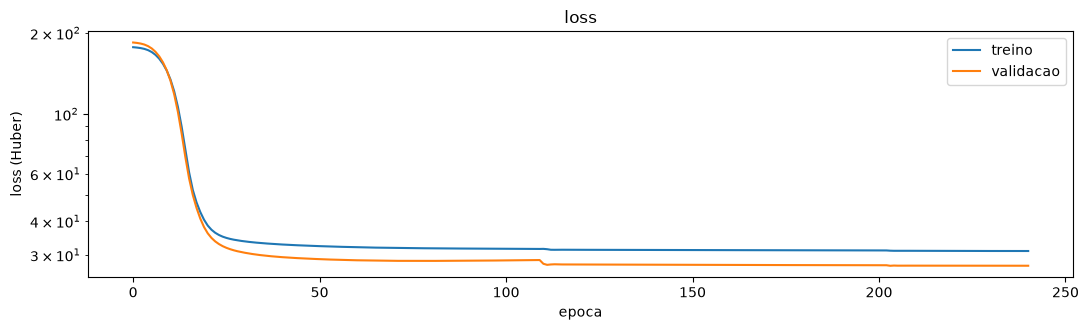

In [72]:
fig, (eixo_loss) = plt.subplots(1, 1, figsize=(11, 3.4))

eixo_loss.plot(historico.history["loss"], label="treino")
eixo_loss.plot(historico.history["val_loss"], label="validacao")
eixo_loss.set_xlabel("epoca")
eixo_loss.set_ylabel("loss (Huber)")
eixo_loss.set_title("loss")
eixo_loss.set_yscale("log")
eixo_loss.legend()

# eixo_mae.plot(historico.history["mae"], label="treino")
# eixo_mae.plot(historico.history["val_mae"], label="validacao")
# eixo_mae.set_xlabel("epoca")
# eixo_mae.set_ylabel("MAE (kW)")
# eixo_mae.set_title("erro absoluto medio")
# eixo_mae.legend()

plt.tight_layout()
plt.show()

In [73]:
pred_keras = modelo.predict(X_tes, batch_size=512, verbose=0).ravel()
resultados.append(avalia("keras (MLP)", y_tes, pred_keras))

keras (MLP)          MAE 6.7686 kW | RMSE 7.8848 kW | R2 0.9089 | vies +6.2546 kW


## 7. Comparação

In [74]:
tabela = pd.DataFrame(resultados).set_index("modelo").round(4)
tabela

,MAE (kW),RMSE (kW),R2,MAE com clip (kW),vies (kW)
modelo,,,,,
media do treino,21.4791,26.2138,-0.0075,21.4791,2.2586
random forest,3.2483,4.4397,0.9711,3.2483,1.9909
keras (MLP),6.7686,7.8848,0.9089,6.7686,6.2546


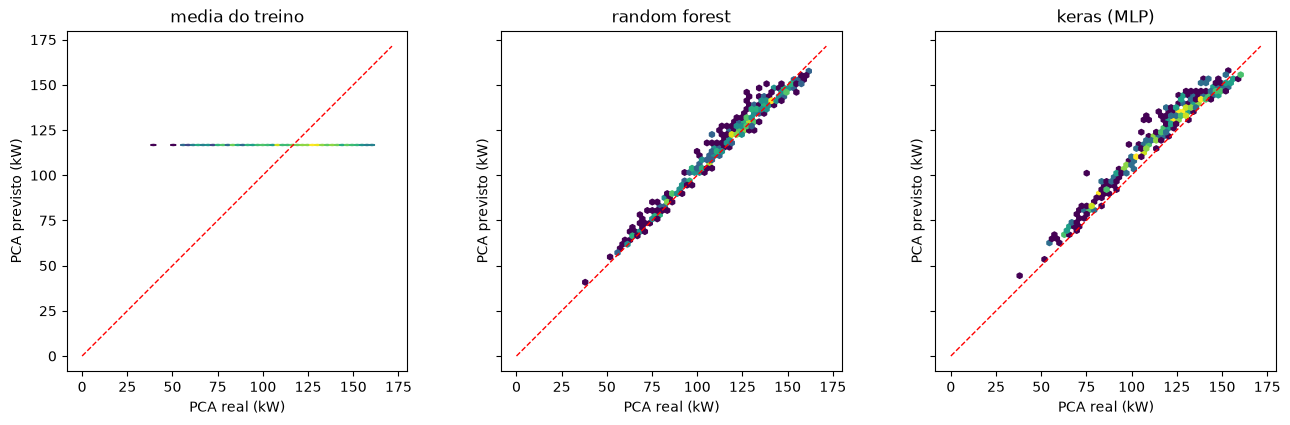

In [75]:
fig, eixos = plt.subplots(1, 3, figsize=(13.5, 4.2), sharey=True)
eixos[0].set_ylabel("PCA previsto (kW)")
plots.hexbin_real_vs_pred(eixos[0], y_tes, media.predict(X_tes).ravel(),
                          "media do treino")
plots.hexbin_real_vs_pred(eixos[1], y_tes, pred_rf, "random forest")
plots.hexbin_real_vs_pred(eixos[2], y_tes, pred_keras, "keras (MLP)")
plt.tight_layout()
plt.show()


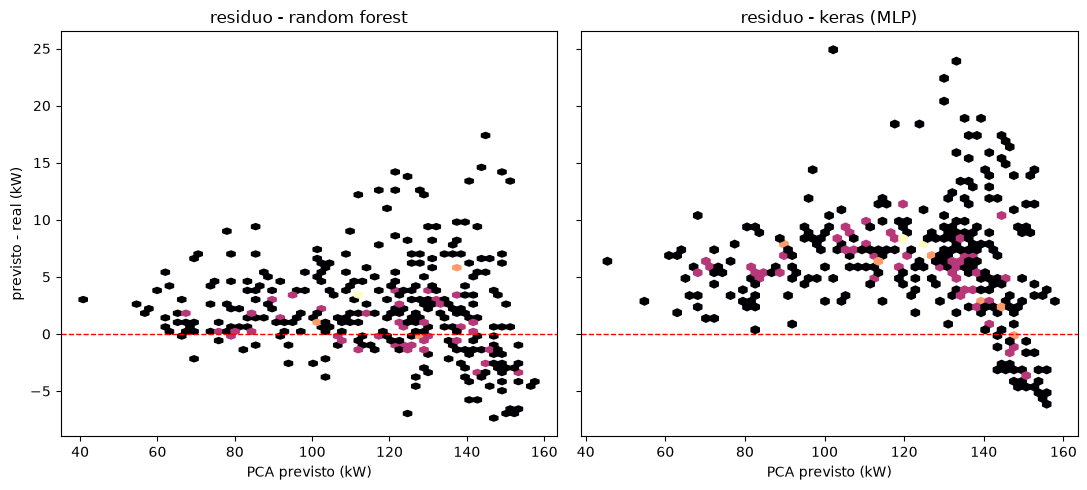

In [76]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 5), sharey=True)

for eixo, nome, pred in (
    (eixos[0], "random forest", pred_rf),
    (eixos[1], "keras (MLP)", pred_keras),
):
    plots.hexbin_residuo(eixo, y_tes, pred, f"residuo - {nome}")

eixos[0].set_ylabel("previsto - real (kW)")
plt.tight_layout()
plt.show()


## 8. Exportação para o Edge Impulse

Regras do *Bring Your Own Model* que restringem o que sai daqui:

- **formatos aceitos**: TensorFlow SavedModel (`.zip`), ONNX (`.onnx`) ou LiteRT
  (`.tflite`). **`.h5` não entra pelo Studio** — o caminho é o SavedModel.
- o `.zip` precisa conter um diretório `saved_model/` com o `saved_model.pb` dentro
- **1 tensor de entrada e 1 de saída**, ambos com dimensão de batch
- **o batch tem que ser 1**: entrada `(1, n_features)` — as features do contrato — e para
  regressão a saída **tem que ser `(1, 1)`**, exatamente o formato desta rede
- a quantização int8 é opcional e só vale para upload em SavedModel/ONNX; ela pede um
  `.npy` em que **cada elemento tem a forma da entrada do modelo** — daí o `(n, 1, n_features)`

O modelo treinado tem batch dinâmico (`None, n_features`). A assinatura vira `(1, n_features)` na
exportação, sem retreinar: nenhum peso muda. Quem faz isso é `mlp.export()`.


In [77]:
escritos = mlp.export(modelo, dados, MINIMO, MAXIMO, destino=SAIDA)
print(f"{SAIDA.name}/")
for caminho, tamanho in escritos.items():
    print(f"   {caminho.name:24} {tamanho / 1024:8.1f} KB")


INFO:tensorflow:Assets written to: C:\Users\gusta\Documents\PlatformIO\Projects\knob-senses\data\modelo_exportado\saved_model\assets


INFO:tensorflow:Assets written to: C:\Users\gusta\Documents\PlatformIO\Projects\knob-senses\data\modelo_exportado\saved_model\assets


modelo_exportado/
   modelo_edge_impulse.zip     313.9 KB
   modelo.tflite               167.4 KB
   dados_representativos.npy     11.6 KB
   normalizacao.json             0.9 KB


In [78]:
# O mlp.export ja escreveu o zip, o .tflite e os dados representativos; aqui so
# conferimos o que o Studio vai receber.
import zipfile

caminho_zip = SAIDA / "modelo_edge_impulse.zip"
with zipfile.ZipFile(caminho_zip) as z:
    assert z.testzip() is None, "zip corrompido"
    nomes = z.namelist()
assert "saved_model/saved_model.pb" in nomes, nomes

caminho_tflite = SAIDA / "modelo.tflite"
caminho_npy = SAIDA / "dados_representativos.npy"
amostra = np.load(caminho_npy)
assert amostra.shape[1:] == (1, len(FEATURES)), amostra.shape

print(f"{caminho_zip.name}  {caminho_zip.stat().st_size / 1024:.1f} KB  "
      f"({len(nomes)} arquivos, saved_model/saved_model.pb presente)")
print(f"{caminho_tflite.name}  {caminho_tflite.stat().st_size / 1024:.1f} KB")
print(f"{caminho_npy.name}  {amostra.shape}  {caminho_npy.stat().st_size / 1024:.1f} KB")


modelo_edge_impulse.zip  313.9 KB  (4 arquivos, saved_model/saved_model.pb presente)
modelo.tflite  167.4 KB
dados_representativos.npy  (980, 1, 3)  11.6 KB
